## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}

## 1) Descripción del problema **[1 pts]**

Un equipo de electrónica está diseñando un prototipo sobre una protoboard. Sobre ella se han ubicado diferentes componentes que deben quedar conectados entre sí.
El problema es que se desea utilizar la menor cantidad posible de cable.

Para resolverlo, cada componente será representado como un vértice, cada posible conexión mediante cable será una arista y la longitud del cable será el peso de la arista.

El objetivo será construir un Árbol de Expansión Mínima (MST) que conecte todos los componentes utilizando la menor longitud total de cable.
Para este laboratorio no se evaluará el funcionamiento electrónico del circuito. La protoboard se utilizará como representación espacial del problema.


## 2) Requerimientos **[2 pts]**

**REQUERIMIENTOS FUNCIONALES**
- RQF1: El sistema debe mostrar una representación gráfica de la protoboard con columnas del 1 al 30 y filas de la A a la J.
- RQF2: El sistema debe ubicar los componentes en las posiciones indicadas: Fuente (F), LED (L), Sensor (S), Pulsador (P), Buzzer (B), Potenciómetro (R) y Microcontrolador (M).
- RQF3: El sistema debe representar cada componente como un vértice del grafo.
- RQF4: El sistema debe calcular la distancia entre cada pareja de componentes utilizando sus posiciones en la protoboard.
- RQF5: El sistema debe representar cada posible conexión como una arista y mostrar su peso.
- RQF6: El sistema debe mostrar gráficamente todas las posibles conexiones entre los componentes con sus respectivas distancias.
- RQF7: El sistema debe aplicar el algoritmo de Kruskal para seleccionar las conexiones de menor peso, evitando que se formen ciclos.
- RQF8: El sistema debe mostrar el Árbol de Expansión Mínima conectando todos los componentes con n-1 conexiones.
- RQF9: El sistema debe mostrar la longitud de cada cable seleccionado y la longitud total utilizada.
- RQF10: El sistema debe permitir cambiar la posición de uno de los componentes, calcular nuevamente las distancias y el Árbol de Expansión Mínima.
- RQF11: El sistema debe mostrar la longitud total de cable antes y después del cambio de posición e indicar si aumentó o disminuyó.


**REQUERIMIENTOS NO FUNCIONALES**
- RQNF1: (Usabilidad) El sistema debe mostrar los componentes, sus posiciones y las conexiones de forma clara para que el usuario pueda entender los resultados.
- RQNF2: (Mantenimiento) El sistema debe estar organizado en funciones para facilitar la revisión y actualización del código.
- RQNF3: (Precisión) El sistema debe calcular las distancias a partir de las posiciones de los componentes, evitando ingresar manualmente los pesos de las conexiones.
- RQNF4: (Restricciónes) El sistema debe implementar manualmente el algoritmo de Kruskal, sin utilizar librerías que calculen directamente el Árbol de Expansión Mínima.
- RQNF5: (Confiabilidad) El Árbol de Expansión Mínima debe conectar todos los componentes, no formar ciclos y tener una cantidad de conexiones igual al número de componentes menos uno.
- RQNF6: (Actualización) Al cambiar la posición del Buzzer, el sistema debe actualizar las conexiones, los resultados y la representación gráfica.



## 3) Historias de usuario **[2 pts]**
Historia de usuario 1

Como usuario, quiero visualizar la protoboard de forma grafica, manteniendo la cantidad de columnas y filas, para ubicar los componentes y entender como se construye el grafo.

CA:
- El sistema debe mostrar las columnas del 1 al 30.
- El sistema debe mostrar las filas de la A a la J.
- El sistema debe ubicar los componentes en sus posiciones correspondientes.
- El sistema debe calcular la distancia entre los componentes utilizando la ecuacion:
  Distancia = |columna1 - columna2| + |fila1 - fila2|.
- El sistema debe mostrar las distancias calculadas y la construccion del grafo.



Historia de usuario 2
Como usuario, quiero visualizar todas las conexiones posibles entre los componentes con su respectivo peso, para conocer las distancias antes de calcular el arbol de Expansion Minima.

CA:
- El sistema debe calcular automaticamente los pesos de las conexiones.
- El sistema debe mostrar todas las conexiones posibles entre los componentes.
- Cada conexion debe mostrar su peso correspondiente.


Historia de usuario 3

Como usuario, quiero que el sistema calcule el arbol de Expansion Minima con el algoritmo de Kruskal, para conectar todos los componentes utilizando la menor cantidad total de cable.

CA:
- El sistema debe ordenar las conexiones desde la de menor peso hasta la de mayor peso.
- El sistema debe seleccionar las conexiones de menor peso evitando que se formen ciclos.
- El arbol final debe conectar todos los componentes y tener seis conexiones.
- El sistema debe mostrar la longitud de cada cable y la longitud total utilizada.


Historia de usuario 4

Como usuario, quiero cambiar la posicion del componente de H6 a J20 y volver a ejecutar el algoritmo, para comparar la cantidad de cable necesaria antes y despues del cambio.

CA:
- El sistema debe actualizar la posicion del componente.
- El sistema debe calcular nuevamente las conexiones y el arbol de Expansion Minima.
- El sistema debe mostrar la longitud total del MST original y la del MST despues del cambio.
- El sistema debe generar una nueva imagen de la protoboard con las conexiones seleccionadas.
- El sistema debe indicar si la cantidad total de cable aumento o disminuyo.



## 4) Diagramas de flujo **[5 pts]**

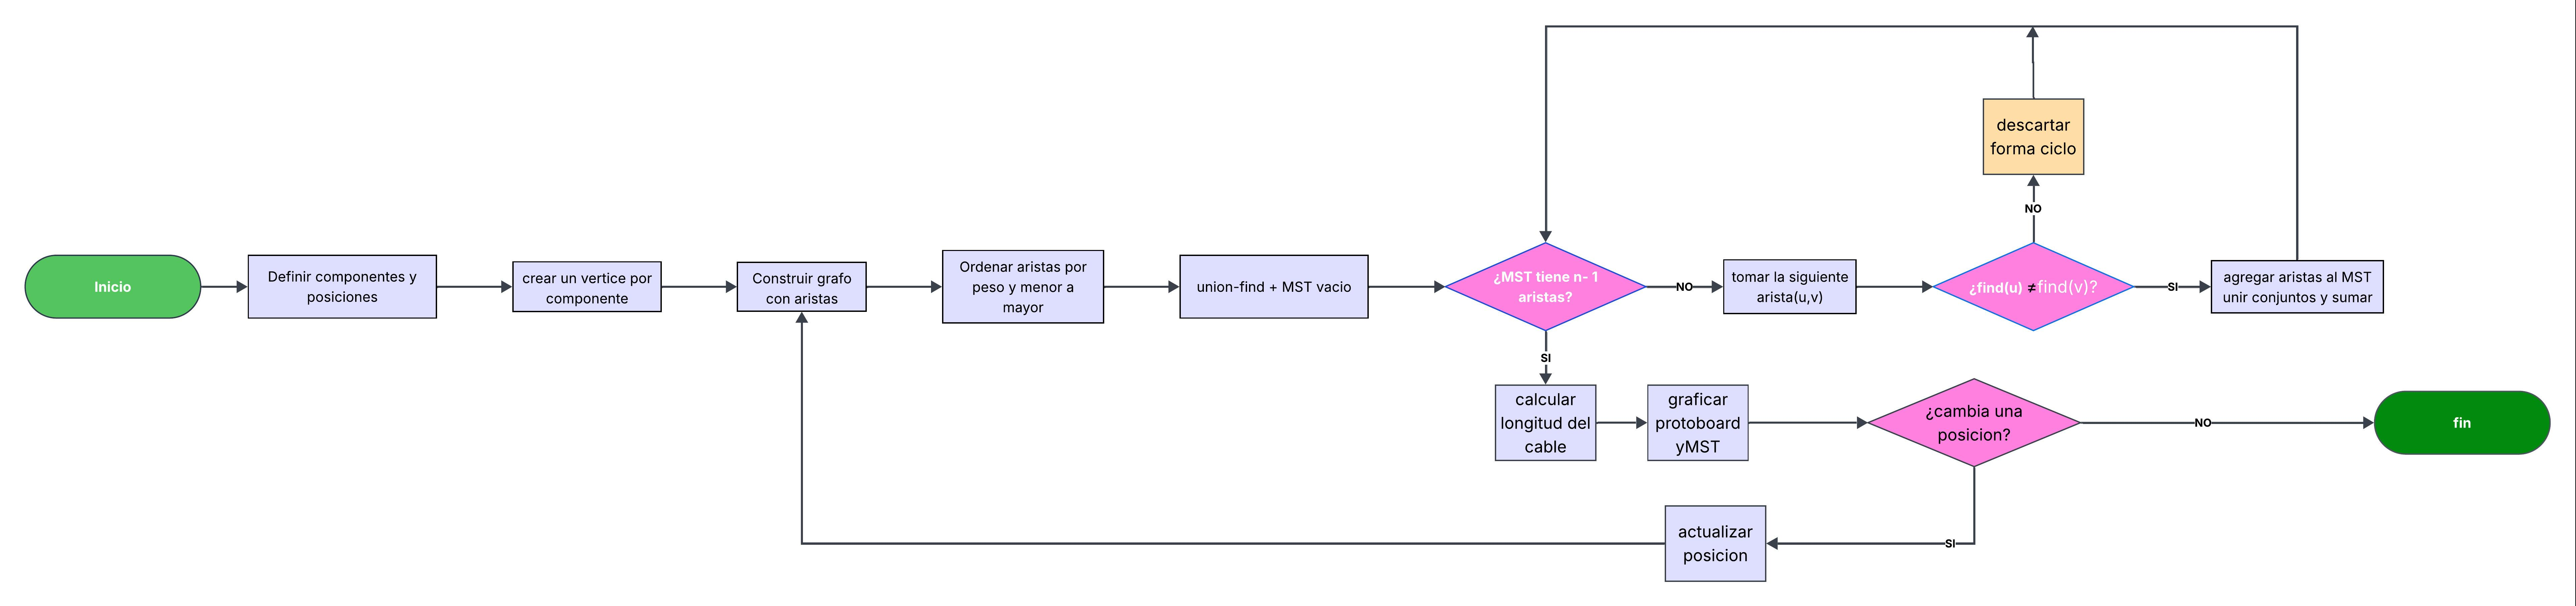

### 5) Análisis de complejidad **[15 pts]**
Funcion: $$O(E log V)$$

Esta complejidad se presenta ya que se deben recorrer las aristas dependiendo de su peso, esto teniendo encuenta principalmente log V, manejando Krustal ordenar la cantidad de aristas E cuesta O(E log E), pero como E < V**2 acaba siendo:

$$O(E log V)$$

Donde E es la cantidad de aristas y V la cantidad de vertices.

El código conecta cada pareja de vértices, así que la cantidad de aristas es E = V * (V - 1) / 2.
Kruskal ordena las E aristas según su peso.
Ordenar esas aristas toma un tiempo proporcional a E * log(V).
Por eso, al aumentar los vértices, crece la cantidad de aristas y el tiempo de ejecución.




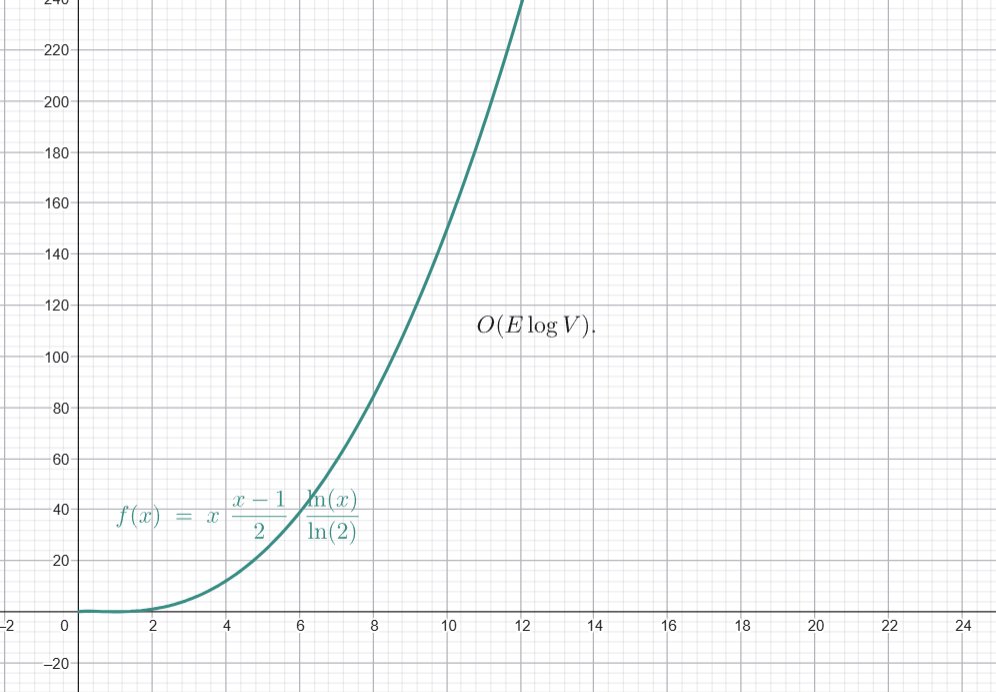

In [ ]:
%pip install matplotlib

## 6) Código funcional **[15 pts]**


In [ ]:
comp = ["F", "L", "S", "P", "B", "R", "M"]
fila = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "H": 8, "I": 9, "J": 10}

def dibujar(pos, aristas, titulo):
    import matplotlib.pyplot as plt

    plt.figure(figsize=(13, 6))
    plt.xlim(1, 30)
    plt.ylim(10.5, 0.5)
    plt.xticks(range(1, 31))
    plt.yticks(range(1, 11), list(fila.keys()))
    plt.grid(True)
    plt.xlabel("Columnas")
    plt.ylabel("Filas")
    plt.title(titulo)

    for d, c1, c2 in aristas:
        x1 = int(pos[c1][1:])
        y1 = fila[pos[c1][0]]
        x2 = int(pos[c2][1:])
        y2 = fila[pos[c2][0]]
        plt.plot([x1, x2, x2], [y1, y1, y2], color="green", linewidth=0.7)
        if x1 != x2:
            plt.text((x1 + x2) / 2, y1 - 0.1, str(d), fontsize=6, color="blue")
        else:
            plt.text(x1 + 0.1, (y1 + y2) / 2, str(d), fontsize=6, color="blue")

    for c in comp:
        x = int(pos[c][1:])
        y = fila[pos[c][0]]
        plt.scatter(x, y, color="red", zorder=3)
        plt.text(x + 0.2, y - 0.2, c, fontsize=9, weight="bold")

    plt.tight_layout()
    plt.show()


def kruskal(pos):
    aris = []
    for i in range(len(comp)):
        for j in range(i + 1, len(comp)):
            c1 = comp[i]
            c2 = comp[j]
            col1 = int(pos[c1][1:])
            col2 = int(pos[c2][1:])
            fil1 = fila[pos[c1][0]]
            fil2 = fila[pos[c2][0]]
            dist = abs(col1 - col2) + abs(fil1 - fil2)
            aris.append((dist, c1, c2))
    aris.sort()

    micasapadre = {}
    for c in comp:
        micasapadre[c] = c

    def buscar(x):
        while micasapadre[x] != x:
            x = micasapadre[x]
        return x

    mst = []
    total = 0
    conex = 0
    for d, c1, c2 in aris:
        r1 = buscar(c1)
        r2 = buscar(c2)
        if r1 != r2:
            micasapadre[r1] = r2
            mst.append((d, c1, c2))
            total = total + d
            conex = conex + 1
            if conex == len(comp) - 1:
                break
    return mst, total, aris


def laboratorio(pos):
    for c in comp:
        if c not in pos:
            print("Falta la posicion de", c)
            return
        p = pos[c].upper()
        if len(p) < 2 or p[0] not in fila or not p[1:].isdigit() or int(p[1:]) < 1 or int(p[1:]) > 30:
            print("Posicion incorrecta para", c)
            return
        pos[c] = p

    dibujar(pos, [], "Protoboard inicial")
    mst, total, aris = kruskal(pos)
    print("Aristas posibles:", len(aris))
    dibujar(pos, aris, "Todas las conexiones posibles")

    print("========== RESULTADO ==========")
    for i in range(len(mst)):
        d, c1, c2 = mst[i]
        print("Cable " + str(i + 1) + ": " + c1 + " - " + c2 + " = " + str(d))
    print("Longitud total de cable:", total, "unidades")
    dibujar(pos, mst, "MST original - longitud total: " + str(total))

    pos_cambio = pos.copy()
    pos_cambio["B"] = "J20"
    mst_cambio, total_cambio, aris_cambio = kruskal(pos_cambio)
    print("MST original")
    print("Longitud total:", total)
    print("MST después del cambio")
    print("Longitud total:", total_cambio)
    dibujar(pos_cambio, mst_cambio, "MST después del cambio - longitud total: " + str(total_cambio))

    if total_cambio > total:
        print("La cantidad total de cable aumentó.")
    elif total_cambio < total:
        print("La cantidad total de cable disminuyó.")
    else:
        print("La cantidad total de cable no cambió.")

    print("Prueba MST:", "correcta" if len(mst) == len(comp) - 1 else "revisar")
    print("Prueba MST con B en J20:", "correcta" if len(mst_cambio) == len(comp) - 1 else "revisar")
    return mst, total, mst_cambio, total_cambio


def ejecutar():
    pos = {}
    for c in comp:
        while True:
            p = input("Posicion de " + c + ": ").upper()
            if len(p) >= 2 and p[0] in fila and p[1:].isdigit():
                col = int(p[1:])
                if col >= 1 and col <= 30:
                    pos[c] = p
                    break
            print("Posicion incorrecta")
    laboratorio(pos)


def pruebas_y_usuario():
    pos_prueba = {"F": "A3", "L": "C8", "S": "B16", "P": "D24", "B": "H6", "R": "I15", "M": "G25"}
    print("Pruebas con las posiciones del enunciado")
    laboratorio(pos_prueba)
    print("Ahora ingresa tus propias posiciones")
    ejecutar()


## 7) Tests aplicados **[15 pts]**

In [ ]:
pos_prueba = {"F": "A3", "L": "C8", "S": "B16", "P": "D24", "B": "H6", "R": "I15", "M": "G25"}
mst_esperado = [(4, "P", "M"), (7, "F", "L"), (7, "L", "B"), (8, "S", "R"), (9, "L", "S"), (10, "S", "P")]

mst, total, aristas = kruskal(pos_prueba)
pos_cambio = pos_prueba.copy()
pos_cambio["B"] = "J20"
mst_cambio, total_cambio, _ = kruskal(pos_cambio)
mst_cambio_esperado = [(4, "P", "M"), (6, "B", "R"), (7, "F", "L"), (8, "B", "M"), (8, "S", "R"), (9, "L", "S")]

assert len(aristas) == 21
assert mst == mst_esperado
assert total == 45
assert len(mst) == len(comp) - 1
assert mst_cambio == mst_cambio_esperado
assert total_cambio == 42
assert len(mst_cambio) == len(comp) - 1

print("PRUEBA DE EJECUCION RAPIDA")
print("Caso original (Buzzer en H6):")
for i, (distancia, c1, c2) in enumerate(mst, start=1):
    print(f"Cable {i}: {c1} - {c2} = {distancia}")
print("Longitud total de cable:", total, "unidades")

print()
print("Caso con el Buzzer en J20:")
for i, (distancia, c1, c2) in enumerate(mst_cambio, start=1):
    print(f"Cable {i}: {c1} - {c2} = {distancia}")
print("Longitud total de cable:", total_cambio, "unidades")
print("Cambio en la longitud:", total_cambio - total, "unidades")
print("La cantidad total de cable disminuyo.")